In [3]:
from c0_env_config_models import *

from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template('给我讲一个关于{topic}的笑话')
model = chat_model
output_parser = StrOutputParser()

chain = prompt | model | output_parser

result = chain.invoke({"topic": "猫和狗"})

In [4]:
print(result)

好的，这是一个关于猫和狗的笑话：

有一天，狗对猫说：“你知道为什么我们总是追着你跑吗？”

猫好奇地问：“为什么呢？”

狗答道：“因为我们需要一个借口，才能离开家去公园玩！”

猫愣了一下，然后回答：“那你们为什么不在公园直接玩呢？”

狗耸耸肩，笑着说：“如果我们在公园玩，那怎么跟主人解释我们一身的泥巴呢？” 

这个笑话以一种幽默的方式展现了猫和狗的“视角”，以及它们与人类生活的互动。


In [5]:
prompt_value = prompt.invoke({"topic": "猫和狗"})

In [6]:
prompt_value

ChatPromptValue(messages=[HumanMessage(content='给我讲一个关于猫和狗的笑话')])

In [7]:
prompt_value.to_messages()

[HumanMessage(content='给我讲一个关于猫和狗的笑话')]

In [8]:
prompt_value.to_string()

'Human: 给我讲一个关于猫和狗的笑话'

In [9]:
message = model.invoke(prompt_value)

In [10]:
message

AIMessage(content='好的，这是一个经典的猫和狗的笑话：\n\n有一天，猫和狗一起去上学。上课时，老师问：“如果我有五只猫，又得到了三只猫，那么我会有几只猫呢？”\n小狗迅速回答：“那您会有八只猫！”\n老师点点头，表示正确。\n\n接着老师又问：“如果我有两栋房子，每栋房子有三间房，那么我有几间房呢？”\n小猫自信地回答：“如果您有两栋房子，每栋房子有三间房，那么您应该会有很多猫住在那里吧！” \n\n这个笑话体现了猫和狗的“思维方式”：小狗注重数学逻辑，而小猫则更关注猫的生活。', response_metadata={'finish_reason': 'stop'})

### Note that if you’re curious about the output of any components, you can always test out a smaller version of the chain such as prompt or prompt | model to see the intermediate results:

In [13]:
(prompt | model).invoke({"topic": "猫和狗"})

AIMessage(content='好的，这是一个关于猫和狗的笑话：\n\n有一天，猫和狗去参加了一个动物智慧比赛。比赛的第一项是看谁能最快地理解并完成任务。裁判对猫说：“你的任务是去那棵树下找到一个红色的球。”猫敏捷地跑过去，很快找到了球。\n\n然后轮到狗，裁判说：“你的任务是帮助盲人过马路。”狗毫不犹豫，立即跑到马路边，找到了一个盲人，温柔地引导他安全地过了马路。\n\n完成任务后，裁判宣布：“这次比赛，你们都表现得非常出色，但我想说的是，虽然猫找到了球，但狗，你赢了。因为，你知道，‘球’只是一个游戏，而‘帮助他人’才是生活。” \n\n猫听后，一脸无奈地说：“好吧，你们总是用人类的规则来评判我们。” \n\n这个笑话既体现了猫的机智，也展示了狗的忠诚和善良，同时也带有一些幽默和自嘲的元素。', response_metadata={'finish_reason': 'stop'})

In [11]:
out=output_parser.invoke(message)

In [12]:
out

'好的，这是一个经典的猫和狗的笑话：\n\n有一天，猫和狗一起去上学。上课时，老师问：“如果我有五只猫，又得到了三只猫，那么我会有几只猫呢？”\n小狗迅速回答：“那您会有八只猫！”\n老师点点头，表示正确。\n\n接着老师又问：“如果我有两栋房子，每栋房子有三间房，那么我有几间房呢？”\n小猫自信地回答：“如果您有两栋房子，每栋房子有三间房，那么您应该会有很多猫住在那里吧！” \n\n这个笑话体现了猫和狗的“思维方式”：小狗注重数学逻辑，而小猫则更关注猫的生活。'

## RunnableParallel & RunnablePassthrough

In [15]:
from langchain_core.runnables import RunnableParallel, RunnablePassthrough

In [14]:
# Using from c0_env_config_models import *
retriever = es_vectorstore.as_retriever()
model = chat_model

In [16]:
template = """Answer the question based only on the following context:
{context}

Question: {question}
"""

In [17]:
template

'Answer the question based only on the following context:\n{context}\n\nQuestion: {question}\n'

In [18]:
prompt = ChatPromptTemplate.from_template(template)
output_parser = StrOutputParser()

In [21]:
question = 'the costs and the threats to America'

### Runnable to passthrough inputs unchanged or with additional keys

In [23]:
RunnablePassthrough().invoke(question)

'the costs and the threats to America'

In [22]:
retriever.invoke(question)

[Document(page_content='Let each of us here tonight in this Chamber send an unmistakable signal to Ukraine and to the world. \n\nPlease rise if you are able and show that, Yes, we the United States of America stand with the Ukrainian people. \n\nThroughout our history we’ve learned this lesson when dictators do not pay a price for their aggression they cause more chaos.   \n\nThey keep moving.   \n\nAnd the costs and the threats to America and the world keep rising.', metadata={'source': 'D:\\JqkjKB\\lc_research\\state_of_the_union.txt'}),
 Document(page_content='Of course, continuing this costs money. \n\nI will soon send Congress a request. \n\nThe vast majority of Americans have used these tools and may want to again, so I expect Congress to pass it quickly.   \n\nFourth, we will continue vaccinating the world.     \n\nWe’ve sent 475 Million vaccine doses to 112 countries, more than any other nation. \n\nAnd we won’t stop. \n\nWe have lost so much to COVID-19. Time with one another.

### RunnableParallel invokes Runnables concurrently, providing the same input to each.

In [19]:
setup_and_retrieval = RunnableParallel(
    {'context':retriever, 'question':RunnablePassthrough()}
)

In [20]:
setup_and_retrieval.invoke()

{'context': [Document(page_content='Let each of us here tonight in this Chamber send an unmistakable signal to Ukraine and to the world. \n\nPlease rise if you are able and show that, Yes, we the United States of America stand with the Ukrainian people. \n\nThroughout our history we’ve learned this lesson when dictators do not pay a price for their aggression they cause more chaos.   \n\nThey keep moving.   \n\nAnd the costs and the threats to America and the world keep rising.', metadata={'source': 'D:\\JqkjKB\\lc_research\\state_of_the_union.txt'}),
  Document(page_content='Of course, continuing this costs money. \n\nI will soon send Congress a request. \n\nThe vast majority of Americans have used these tools and may want to again, so I expect Congress to pass it quickly.   \n\nFourth, we will continue vaccinating the world.     \n\nWe’ve sent 475 Million vaccine doses to 112 countries, more than any other nation. \n\nAnd we won’t stop. \n\nWe have lost so much to COVID-19. Time with

In [24]:
chain = setup_and_retrieval | prompt | model | output_parser

In [25]:
chain.invoke(question)

"The costs and threats to America refer to the consequences of not taking action against dictators' aggression. As mentioned in the context, when dictators do not face consequences, they continue their aggression, leading to more chaos, continuous movement, and increased risks to both America and the world."

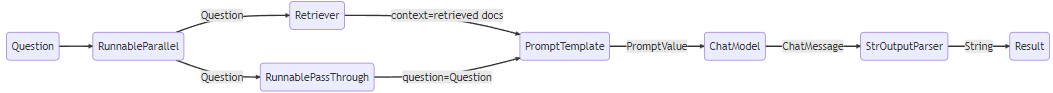